## ___<( Clustring )>___


In [1]:
import mlflow

mlflow.set_tracking_uri('http://127.0.0.1:5000')
mlflow.set_experiment('diabete_risk_prediction')

c:\Users\ycode\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1791392459614, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791392459614, lifecycle_stage='active', name='diabete_risk_prediction', tags={}, trace_location=None, workspace='default'>

In [2]:
import pandas as pd

df = pd.read_csv('../data/cleaned_data.csv')

In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_scaled = scaler.fit_transform(df)

In [10]:
from sklearn.cluster import KMeans
import pandas as pd

# 1. Fit optimal K-Means model with K = 2
kmeans = KMeans(n_clusters=2, random_state=42).fit(x_scaled)
df['cluster'] = kmeans.labels_


# Select your newly engineered columns
features_to_inspect = [
    'Glucose', 
    'BMI',
    'Insulin',
    'DiabetesPedigreeFunction',
]

# 2. Inspect mean values to identify which cluster is High vs Low risk
cluster_profile = df.groupby('cluster')[features_to_inspect].mean()
print(cluster_profile.round(2))


# 3. Map cluster IDs (0 and 1) to readable labels based on Step 2
# (Swap values if cluster 0 turns out to have higher Glucose/BMI)
risk_map = {
    0: 'High Risk',
    1: 'Low Risk'
}

df['risk_tier'] = df['cluster'].map(risk_map)

# the high/low groups changes according to the random_state chosen. 
# in our case 0 is high but it could be the opposite !!!!!

         Glucose    BMI  Insulin  DiabetesPedigreeFunction
cluster                                                   
0         140.72  35.62   205.71                      0.52
1         105.84  29.73   108.54                      0.43


In [5]:
import joblib

joblib.dump(scaler, '../models/scaler.joblib')
joblib.dump(kmeans, '../models/kmeans_k2.joblib')

['../models/kmeans_k2.joblib']

In [6]:
from sklearn.metrics import silhouette_score

sil_score = silhouette_score(x_scaled, kmeans.labels_)
inertia = kmeans.inertia_

with mlflow.start_run(run_name='kmeans_k2_clustering'):

    mlflow.log_param('k', 2)
    mlflow.log_param('scaler', 'StandardScaler')
    mlflow.log_param('random_state', 42)

    mlflow.log_metric('inertia', inertia)
    mlflow.log_metric('silhouette_score', sil_score)


    mlflow.log_artifact('../models/scaler.joblib')
    mlflow.log_artifact('../models/kmeans_k2.joblib')

    print(f"Run terminé — Silhouette: {sil_score:.4f}, Inertia: {inertia:.2f}")

Run terminé — Silhouette: 0.1899, Inertia: 5564.97
🏃 View run kmeans_k2_clustering at: http://127.0.0.1:5000/#/experiments/1/runs/43bd0be1a289409f855353eb69f016f1
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


## K = 2
| Cluster | Glucose | BMI  | DiabetesPedigreeFunction |
|---:|---:|---:|---:|
| 0 | 140.72 | 35.62 | 0.52 |
| 1 | 105.84 | 29.73 | 0.43 |

## k = 3
| Cluster | Glucose | BMI | DiabetesPedigreeFunction |
|---:|---:|---:|---:|
| 0 | 139.13 | 38.66 | 0.59 |
| 1 | 131.63 | 32.48 | 0.44 |
| 2 | 104.26 | 28.63 | 0.42 |

C:\Users\ycode\AppData\Local\Temp\ipykernel_21956\2490322127.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='cluster', data=df, palette=['#2ecc71', '#e74c3c'])


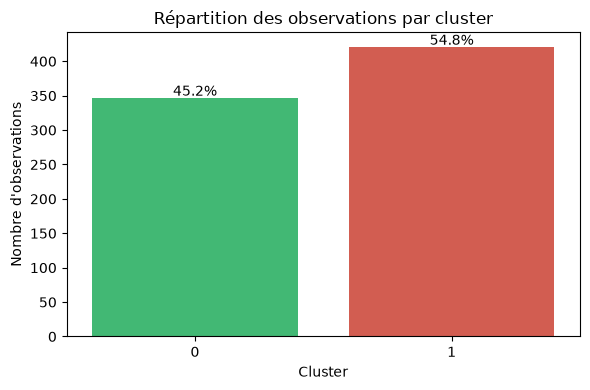

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Countplot — combien d'observations par cluster
plt.figure(figsize=(6, 4))
sns.countplot(x='cluster', data=df, palette=['#2ecc71', '#e74c3c'])
plt.title('Répartition des observations par cluster')
plt.xlabel('Cluster')
plt.ylabel("Nombre d'observations")

# Ajouter les pourcentages sur les barres
total = len(df)
for p in plt.gca().patches:
    pct = f"{100 * p.get_height() / total:.1f}%"
    plt.gca().annotate(pct, (p.get_x() + p.get_width() / 2, p.get_height() + 3), ha='center')

plt.tight_layout()
plt.savefig('../figures/cluster_distribution_k2.png')
plt.show()


In [8]:
print(df['cluster'].value_counts())


cluster
1    421
0    347
Name: count, dtype: int64


In [9]:
import pandas as pd

df.to_csv('../data/clustered_data.csv')